# 05 — Population Dependence of the RAR (SPARC only)

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

## 1. Scope

This notebook implements **proposal Section 4.5** for the SPARC sample. Every RAR parameter may vary linearly with a standardised galaxy property:

  θ_i = θ₀ + θ₁ · z_i,  θ ∈ {log a₀, β, log σ_int, log τ}

z_i is the standardised **log baryonic mass**, **log central disk surface brightness** or **gas fraction**. Each is fitted **one at a time** (the primary analysis) and **jointly** (secondary), as the proposal specifies.

* **Error model:** Model C of Notebook 03, with independent errors and distance, inclination and Υ★ sampled per galaxy. Its likelihood and priors are reused unchanged; with all slopes at zero this notebook's model *is* Notebook 03's Model C, and that is tested. The correlated-error models (D/E, Notebook 04) are not used here. Under them σ_int collapses toward zero, so a σ_int–property relation cannot be tested there; the a₀/β dependence under correlated errors is left as a follow-up.
* **Not applicable:** survey offsets Δ_s and comparisons 5–6 of Sec. 4.5 need non-SPARC samples. The cross-survey feasibility gate (Notebook 01B) did not pass.
* **Test family (declared before seeing results):** the 12 slopes θ₁ (4 parameters × 3 properties) from the one-at-a-time fits. A dependence is called **supported** only if it survives a Bonferroni-corrected two-sided test at family-wise α = 0.05. The joint fit is reported but is not part of the family.
* **Not in this notebook:** injection–recovery and detection limits (Notebook 06), cross-validation (Notebook 07).

**Labels:** `NB03` (read from Notebook 03 files), `FIT` (this notebook), `DERIVED` (diagnostics). Nothing here claims an astrophysical detection unless the declared rule is met **and** the fit converged.

## 2. Environment Setup

In [1]:
import os, sys, importlib.util, subprocess
N_CPU = os.cpu_count() or 1
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={max(1, min(N_CPU, 8))}"
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.isdir("/kaggle/working")
REQUIRED = {"jax": "jax", "numpyro": "numpyro", "xarray": "xarray", "h5netcdf": "h5netcdf", "h5py": "h5py",
            "scipy": "scipy", "matplotlib": "matplotlib", "pandas": "pandas", "mpmath": "mpmath"}
missing = [p for m, p in REQUIRED.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, json, time, glob, hashlib, logging, platform, warnings, resource, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, scipy, scipy.stats as sst, xarray as xr
import matplotlib, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from jax.scipy.linalg import cholesky as jcholesky, solve_triangular
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from numpyro.infer.util import log_density, unconstrain_fn
from jax.scipy.special import ndtr, ndtri
from numpyro.diagnostics import split_gelman_rubin, effective_sample_size
numpyro.enable_x64()
numpyro.set_host_device_count(max(1, min(N_CPU, 8)))

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "jax": jax.__version__, "numpyro": numpyro.__version__, "xarray": xr.__version__, "matplotlib": matplotlib.__version__,
            "cpu_count": N_CPU, "jax_devices": len(jax.devices()), "jax_backend": jax.default_backend(), "x64": bool(jax.config.read("jax_enable_x64"))}
print(f"Run {RUN_ID} | Colab: {IN_COLAB}"); print(VERSIONS)

Run 20261027T161151Z | Colab: True
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'jax': '0.11.1', 'numpyro': '0.22.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0', 'cpu_count': 2, 'jax_devices': 2, 'jax_backend': 'cpu', 'x64': True}


In [2]:
# =====================================================================
# CONFIGURATION
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive"); DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))
if IN_KAGGLE and "RAR_PROJECT_ROOT" not in os.environ:          # optional: also runs unattended on Kaggle
    import shutil
    cands = [p.parent for p in Path("/kaggle/input").rglob("03_Processed_Data") if p.is_dir()]
    full = [c for c in cands if any((c / "05_Results" / "Posterior_Samples").glob("03_bayesian_full_modelC_posterior*.nc"))]
    if not (full or cands): raise FileNotFoundError("Add your RAR_Universality_Research dataset as a Kaggle input.")
    src = sorted(full or cands, key=lambda p: len(p.parts))[0]
    PROJECT_ROOT = Path("/kaggle/working/RAR_Universality_Research")
    if not PROJECT_ROOT.exists(): shutil.copytree(src, PROJECT_ROOT, ignore=shutil.ignore_patterns("01_Datasets"))
PROC = PROJECT_ROOT / "03_Processed_Data"
DIRS = {"processed": PROC, "models": PROJECT_ROOT / "04_Trained_Models", "tables": PROJECT_ROOT / "05_Results" / "Tables",
        "posterior": PROJECT_ROOT / "05_Results" / "Posterior_Samples", "logs": PROC / "logs"}           # read-only inputs
NB02 = {"points": PROC / "sparc_rar_points_baseline.csv", "galaxies": PROC / "sparc_rar_galaxies_baseline.csv", "npz": PROC / "sparc_rar_model_inputs.npz"}
AUDIT01 = PROC / "sparc_galaxy_audit.csv"            # Notebook 01: derived Mbar and gas fraction (documented fiducial definitions)
NB03_RUN_ID = os.environ.get("RAR_NB03_RUN_ID", "")
OUT_ROOT = PROJECT_ROOT / "05_Results" / "Population_Dependence" / RUN_ID       # new, versioned; never overwrites
OUT = {k: OUT_ROOT / k for k in ("posterior", "tables", "figures", "diagnostics", "config", "logs")}

KPC_IN_M, KMS_IN_MS, LN10 = 3.0856775814913673e19, 1.0e3, float(np.log(10.0))
REF = {"a0": 1.20e-10, "beta": 0.5, "upsilon_disk": 0.5, "upsilon_bulge": 0.7}
UPS_SIGMA_DEX = {"D": 0.10, "E": 0.20}             # Model C uses the 0.10 dex width (verified against Notebook 03)

# ---------------- Population model (proposal Sec. 4.5) ----------------
COVARIATES = {   # name: (definition, source)
    "logMbar": ("log10 baryonic mass [Msun] = log10(1.33 M_HI + 0.5 L[3.6]); Notebook 01 fiducial definition", "sparc_galaxy_audit.csv"),
    "logSB0":  ("log10 central disk surface brightness at 3.6 um [Lsun/pc^2] (SPARC SBdisk)", "sparc_rar_galaxies_baseline.csv"),
    "fgas":    ("gas fraction 1.33 M_HI / Mbar (Notebook 01 fiducial definition)", "sparc_galaxy_audit.csv"),
}
POP_PARAMS = ["log10_a0", "beta", "log_sigma_int", "log_tau"]
# Slope priors (per 1 SD of the covariate). They are not specified by the proposal: weakly informative regularisation choices,
# with a x2 sensitivity test. The intercepts (values at the sample-mean property) keep Notebook 03's priors exactly.
SLOPE_PRIOR_SD = {"log10_a0": 0.25,      # dex of a0 per SD
                  "beta": 0.10,          # beta per SD
                  "log_sigma_int": 0.5,  # natural-log units per SD (x1.65 per SD at 1 sigma)
                  "log_tau": 0.5}
BETA_FLOOR = 0.01                         # beta_i <= floor is outside the RAR's domain (zero likelihood); reported if ever approached
FITS_ONE_AT_A_TIME = list(COVARIATES)     # primary analysis
RUN_JOINT_FIT = True                      # secondary analysis (all three covariates together)
RUN_PRIOR_SENSITIVITY = os.environ.get("RAR_PRIOR_SENS", "1") == "1"   # one-at-a-time fits again with slope prior SD x2
FAMILY_ALPHA = 0.05                       # family-wise error rate over the declared test family (12 slopes)

# ---------------- Sampler (Notebook 03 settings; Model C converged with them) ----------------
SEED = 20261027
TARGET_ACCEPT, MAX_TREE_DEPTH = 0.90, 10
FIT = {"chains": int(os.environ.get("RAR_CHAINS", 4)), "warmup": int(os.environ.get("RAR_WARMUP", 1000)), "samples": int(os.environ.get("RAR_SAMPLES", 1500))}
RHAT_MAX, ESS_BULK_MIN, ESS_TAIL_MIN, DIVERGENCES_MAX, BFMI_MIN = 1.01, 400, 400, 0, 0.3
ILOO = {"post_draws": int(os.environ.get("RAR_ILOO_DRAWS", 300)), "mc": int(os.environ.get("RAR_ILOO_MC", 64))}
ALLOW_OVERWRITE = False
PROGRESS = not IN_KAGGLE
print("Project root:", PROJECT_ROOT); print("Outputs ->", OUT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research
Outputs -> /content/drive/MyDrive/RAR_Universality_Research/05_Results/Population_Dependence/20261027T161151Z


## 3. Google Drive Mounting and Logging

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
if OUT_ROOT.exists() and any(OUT_ROOT.iterdir()):
    raise FileExistsError(f"{OUT_ROOT} already exists and is not empty; refusing to overwrite")
for d in OUT.values():
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = OUT["logs"] / f"05_population_{RUN_ID}.log"
logger = logging.getLogger("rar05"); logger.setLevel(logging.INFO); logger.handlers.clear(); logger.propagate = False
_fh = logging.FileHandler(LOG_PATH, encoding="utf-8"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    if status == "FAIL":
        raise RuntimeError(f"Critical check failed: {section} | {name} | {detail}")
    return bool(passed)

def safe_path(path: Path) -> Path:
    if path.exists() and not ALLOW_OVERWRITE:
        new = path.with_name(f"{path.stem}_{RUN_ID}{path.suffix}"); logger.info(f"{path.name} exists; writing {new.name}"); return new
    return path

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Log:", LOG_PATH)

Mounted at /content/drive
Log: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Population_Dependence/20261027T161151Z/logs/05_population_20261027T161151Z.log


## 4. Loading Notebook 03 Outputs

The Notebook 03 run with a completed, converged full Model C is located, and its priors are verified. Model C's posterior is used for the regression test, for initialisation and as the reference.

In [4]:
cfgs = []
for p in sorted(DIRS["models"].glob("03_bayesian_sampler_config*.json")):
    try:
        c = json.loads(p.read_text()); cm = c.get("full", {}).get("completed_models", {})
        cfgs.append({"file": p.name, "run_id": c.get("run_id"), "created": c.get("created_utc"), "full_models": ",".join(cm), "cfg": c})
    except Exception as exc:
        logger.warning(f"Could not read {p.name}: {exc}")
cfg_table = pd.DataFrame(cfgs)
display(cfg_table.drop(columns="cfg") if len(cfg_table) else "no Notebook 03 configurations found")
cands = [c for c in cfgs if "C" in c["full_models"].split(",") and (not NB03_RUN_ID or c["run_id"] == NB03_RUN_ID)]
record_check("NB03", "a Notebook 03 run with a completed full Model C exists", bool(cands), f"{len(cands)} candidate runs")
nb03 = max(cands, key=lambda c: c["created"]); CFG03 = nb03["cfg"]; RUN03 = nb03["run_id"]
print(f"Using Notebook 03 run {RUN03} (config {nb03['file']})")

def run_file(folder, stem, ext):
    # File written by run RUN03: suffixed name if present, else the base name.
    p1 = folder / f"{stem}_{RUN03}{ext}"; p0 = folder / f"{stem}{ext}"
    return p1 if p1.is_file() else p0

NC03 = {}
for m, info in CFG03["full"]["completed_models"].items():
    p = Path(info["netcdf"])
    if not p.is_file():                                         # stored path may be absolute from another mount; fall back to folder
        p = DIRS["posterior"] / Path(info["netcdf"]).name
    record_check("NB03", f"Model {m} posterior file exists", p.is_file(), str(p))
    attrs = xr.open_dataset(p, group="posterior", engine="h5netcdf").attrs
    record_check("NB03", f"Model {m} posterior carries run ID {RUN03}", attrs.get("run_id") == RUN03, f"file run_id {attrs.get('run_id')}")
    st = info["stats"]
    record_check("NB03", f"Model {m} met all convergence criteria in Notebook 03", bool(st["converged_by_all_criteria"]),
                 f"max R-hat {st['max_r_hat_all']:.4f}, min ESS {st['min_ess_bulk_all']:.0f}, divergences {st['divergences']}",
                 severity="warning" if os.environ.get("RAR_TEST_ALLOW_UNCONVERGED_NB03") == "1" else "critical")   # override: local testing only
    NC03[m] = p
chk03_path = run_file(DIRS["processed"], "03_bayesian_integrity_checks", ".csv")
chk03 = pd.read_csv(chk03_path)
record_check("NB03", "Notebook 03 check register has no FAIL rows", int((chk03.status == "FAIL").sum()) == 0,
             f"{chk03_path.name}: {len(chk03)} checks, {int((chk03.status=='FAIL').sum())} FAIL, {int((chk03.status=='WARN').sum())} WARN")
print("Notebook 03 warnings:"); display(chk03[chk03.status == "WARN"][["section", "check", "detail"]])
comp03_path = run_file(DIRS["tables"], "03_bayesian_model_comparison", ".csv")
comp03 = pd.read_csv(comp03_path) if comp03_path.is_file() else pd.DataFrame()
if len(comp03):
    display(comp03[[c for c in comp03.columns if c in ("stage", "model", "elpd_loo_galaxy", "p_loo", "n_pareto_k_gt_0.7", "sigma_int_median", "tau_median")]])
    bad_k = comp03[(comp03.get("n_pareto_k_gt_0.7", 0) > 0.1 * comp03.get("n_galaxies", 1))]
    record_check("NB03", "Notebook 03 galaxy-level PSIS-LOO reliable (Pareto k > 0.7 in < 10% of galaxies)", bad_k.empty,
                 bad_k[["stage", "model", "n_pareto_k_gt_0.7"]].values.tolist() if not bad_k.empty else "ok", severity="warning")

# Shared priors must be identical to Notebook 03
P03 = CFG03["priors"]
same_priors = (P03["log10_a0"]["low"] == -11.5 and P03["log10_a0"]["high"] == -8.5 and P03["beta"]["low"] == 0.05 and P03["beta"]["high"] == 1.0
               and P03["sigma_int"]["scale"] == 0.1 and P03["tau"]["scale"] == 0.1 and P03["upsilon_disk"]["sigma_dex"] == UPS_SIGMA_DEX["D"]
               and P03["upsilon_disk"]["median"] == REF["upsilon_disk"] and P03["upsilon_bulge"]["median"] == REF["upsilon_bulge"]
               and P03["inclination"]["low"] == 1.0 and P03["inclination"]["high"] == 90.0)
record_check("NB03", "shared priors in this notebook equal Notebook 03's saved priors", same_priors, "log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds")
record_check("NB03", "Sigma_x convention unchanged (0: no documented baryonic-component errors)", CFG03.get("sigma_x_log_gbar", None) == 0.0, "0.0")

,file,run_id,created,full_models
0,03_bayesian_sampler_config.json,20261022T095219Z,2026-10-22T09:52:19Z,
1,03_bayesian_sampler_config_20261022T095735Z.json,20261022T095735Z,2026-10-22T09:57:35Z,"C,A,B"


INFO: [PASS] NB03 | a Notebook 03 run with a completed full Model C exists | 1 candidate runs
Using Notebook 03 run 20261022T095735Z (config 03_bayesian_sampler_config_20261022T095735Z.json)
INFO: [PASS] NB03 | Model C posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelC_posterior.nc
INFO: [PASS] NB03 | Model C posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model C met all convergence criteria in Notebook 03 | max R-hat 1.0014, min ESS 2962, divergences 0
INFO: [PASS] NB03 | Model A posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelA_posterior.nc
INFO: [PASS] NB03 | Model A posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model A met all convergence criteria in Notebook 03 | max R-hat 1.0026, min ESS 1913, divergences 0
INFO: [PASS] NB03 | Model B poste

,section,check,detail
17,Positivity,every point excluded by the rule was also non-...,"rule excludes [('DDO064', 0), ('UGC01281', 0),..."


,stage,model,elpd_loo_galaxy,p_loo,n_pareto_k_gt_0.7,sigma_int_median,tau_median
0,PILOT (validation only),C,135.761034,58.684227,5,0.060355,0.186125
1,FULL,A,3084.192629,47.431458,3,0.057298,0.155636
2,FULL,B,3151.837121,64.228407,4,0.045952,0.147108
3,FULL,C,3661.801975,379.460001,88,0.035569,0.121956


INFO: [PASS] NB03 | shared priors in this notebook equal Notebook 03's saved priors | log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds
INFO: [PASS] NB03 | Sigma_x convention unchanged (0: no documented baryonic-component errors) | 0.0


True

## 5. Verifying the SPARC Analysis Sample

Same inputs (checksums) and the same 3,164 likelihood points as Notebook 03, using the positivity rule reproduced with Notebook 03's seed.

In [5]:
for k in ("points", "galaxies", "npz"):
    rec = CFG03["input_checksums"].get(NB02[k].name)
    record_check("Sample", f"{NB02[k].name} unchanged since Notebook 03", rec is not None and sha256_of(NB02[k]) == rec, "SHA-256 compared")
pts = pd.read_csv(NB02["points"]); gals = pd.read_csv(NB02["galaxies"])
npz = np.load(NB02["npz"])
p_sorted = pts.sort_values(["galaxy_index", "point_index"]).reset_index(drop=True)
gtab = gals.sort_values("galaxy_index").reset_index(drop=True)
G = len(gtab); gi = p_sorted.galaxy_index.to_numpy(np.int32)
R0, V0, eV0 = npz["R_kpc"], npz["Vobs_kms"], npz["errV_kms"]
Vg0, Vd0, Vb0 = npz["Vgas_kms"], npz["Vdisk_ups1_kms"], npz["Vbul_ups1_kms"]
D0, eD0 = gtab.distance_mpc.to_numpy(float), gtab.e_distance_mpc.to_numpy(float)
I0, eI0 = gtab.inc_deg.to_numpy(float), gtab.e_inc_deg.to_numpy(float)
has_bulge = p_sorted.groupby("galaxy_index").Vbul.apply(lambda s: bool((s > 0).any())).reindex(range(G)).to_numpy()

# Positivity rule exactly as Notebook 03 (same seed and draw count); E's wider prior is evaluated for information only
def positivity(sig_dex, seed, n):
    rng = np.random.default_rng(seed)
    ud = 10 ** (np.log10(REF["upsilon_disk"]) + sig_dex * rng.standard_normal(n))
    ub = 10 ** (np.log10(REF["upsilon_bulge"]) + sig_dex * rng.standard_normal(n))
    p = np.ones(len(R0))
    for k in np.where(Vg0 <= 0)[0]:
        p[k] = float(np.mean(ud * Vd0[k] ** 2 + ub * Vb0[k] ** 2 + Vg0[k] * abs(Vg0[k]) > 0))
    return p
pos = CFG03["positivity_rule"]
p_pos = positivity(UPS_SIGMA_DEX["D"], CFG03["seed"], pos["mc_draws"])
gbar_ref = (Vg0 * np.abs(Vg0) + 0.5 * Vd0 ** 2 + 0.7 * Vb0 ** 2)
include = (p_pos >= pos["P_prior_min"]) & (gbar_ref > 0)
excl = sorted(zip(p_sorted.galaxy[~include], p_sorted.point_index[~include].astype(int)))
record_check("Sample", f"point set reproduces Notebook 03 ({pos['n_points_included']} points)", int(include.sum()) == pos["n_points_included"], f"{int(include.sum())}")
record_check("Sample", "excluded points identical to Notebook 03", [list(map(lambda v: v if isinstance(v, str) else int(v), e)) for e in excl] == pos["excluded_points"], excl)


INFO: [PASS] Sample | sparc_rar_points_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_galaxies_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_model_inputs.npz unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | point set reproduces Notebook 03 (3164 points) | 3164
INFO: [PASS] Sample | excluded points identical to Notebook 03 | [('DDO064', 0), ('UGC01281', 0), ('UGC01281', 1), ('UGC07577', 0)]


True

## 6. Galaxy Properties (covariates)

Catalogue values are used: SPARC distance and the fiducial Υ★ = 0.5 that Notebook 01 used for its derived quantities. The covariates are **predictors**. They are not re-derived from the sampled distances and Υ★, which would make them depend on the parameters being fitted. Each is standardised over the 153-galaxy sample (mean 0, SD 1), so the intercepts are the RAR parameters at the sample-average galaxy.

In [6]:
aud = pd.read_csv(AUDIT01)
cov = gtab[["galaxy", "galaxy_index", "SBdisk0_Lsun_pc2"]].merge(aud[["galaxy", "Mbar_1e9Msun_derived_fid", "fgas_derived_fid", "MHI_1e9Msun", "L36_1e9Lsun"]], on="galaxy", how="left")
cov["logMbar"] = np.log10(cov.Mbar_1e9Msun_derived_fid * 1e9)
cov["logSB0"] = np.log10(cov.SBdisk0_Lsun_pc2)
cov["fgas"] = cov.fgas_derived_fid
recheck = np.allclose(cov.Mbar_1e9Msun_derived_fid, 1.33 * cov.MHI_1e9Msun + 0.5 * cov.L36_1e9Lsun, rtol=1e-6)
record_check("Covariates", "Mbar reproduces 1.33 M_HI + 0.5 L[3.6] (Notebook 01 definition)", recheck, "")
record_check("Covariates", "galaxy order equals the model-input order", list(cov.galaxy_index) == list(range(G)), f"{G} galaxies")
for c in COVARIATES:
    record_check("Covariates", f"{c} finite for all {G} galaxies", bool(np.isfinite(cov[c]).all()), f"{int((~np.isfinite(cov[c])).sum())} non-finite")
COV_MEAN = {c: float(cov[c].mean()) for c in COVARIATES}; COV_SD = {c: float(cov[c].std(ddof=0)) for c in COVARIATES}
Zall = np.column_stack([(cov[c] - COV_MEAN[c]) / COV_SD[c] for c in COVARIATES])
cov_corr = pd.DataFrame(np.corrcoef(Zall.T), index=list(COVARIATES), columns=list(COVARIATES))
vif = {c: float(np.linalg.inv(cov_corr.values)[k, k]) for k, c in enumerate(COVARIATES)}
print("Covariate summary (physical units):"); display(cov[list(COVARIATES)].describe().T)
print("Correlation matrix of the standardised covariates:"); display(cov_corr.round(3))
print("Variance inflation factors (joint fit):", {k: round(v, 2) for k, v in vif.items()})
if max(vif.values()) > 2.5:
    logger.warning("Covariates are strongly correlated: joint-fit slopes will be partly degenerate. The one-at-a-time fits are primary (declared).")
cov_table = cov[["galaxy", "logMbar", "logSB0", "fgas"]].assign(**{f"z_{c}": Zall[:, k] for k, c in enumerate(COVARIATES)})

INFO: [PASS] Covariates | Mbar reproduces 1.33 M_HI + 0.5 L[3.6] (Notebook 01 definition) | 
INFO: [PASS] Covariates | galaxy order equals the model-input order | 153 galaxies
INFO: [PASS] Covariates | logMbar finite for all 153 galaxies | 0 non-finite
INFO: [PASS] Covariates | logSB0 finite for all 153 galaxies | 0 non-finite
INFO: [PASS] Covariates | fgas finite for all 153 galaxies | 0 non-finite
Covariate summary (physical units):


,count,mean,std,min,25%,50%,75%,max
logMbar,153.0,9.827318,0.949282,7.690728,9.215529,9.785799,10.663295,11.429540
logSB0,153.0,2.642165,0.689011,1.324899,2.060849,2.592832,3.172831,4.376830
fgas,153.0,0.449970,0.271471,0.015500,0.185615,0.443737,0.678258,0.945325


Correlation matrix of the standardised covariates:


,logMbar,logSB0,fgas
logMbar,1.000,0.659,-0.769
logSB0,0.659,1.000,-0.742
fgas,-0.769,-0.742,1.000


Variance inflation factors (joint fit): {'logMbar': 2.56, 'logSB0': 2.32, 'fgas': 3.21}


## 7. Likelihood (Notebook 03 Model C, galaxy-specific parameters)

`accelerations`, `f_rar`, `fprime_rar`, `residual_terms` and `galaxy_loglik_C` are byte-identical to Notebooks 03/04. `galaxy_loglik_pop` is the same Sherman–Morrison likelihood with a₀, β, σ_int and τ allowed to differ between galaxies. With all slopes at zero it must reproduce Notebook 03 exactly (Section 8).

In [7]:
def accelerations(D, inc_deg, ups_d, ups_b, idx, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=jnp):
    sD = (D / D0)[idx]
    s_inc = (xp.sin(xp.deg2rad(I0)) / xp.sin(xp.deg2rad(inc_deg)))[idx]
    R_m = R0 * sD * KPC_IN_M
    Vobs, eV = V0 * s_inc, eV0 * s_inc
    vbar2 = (Vg0 * xp.abs(Vg0) + ups_d[idx] * Vd0 ** 2 + ups_b[idx] * Vb0 ** 2) * sD
    g_obs = (Vobs * KMS_IN_MS) ** 2 / R_m
    g_bar = vbar2 * KMS_IN_MS ** 2 / R_m
    sig_V = 2.0 * eV / (Vobs * LN10)
    return g_obs, g_bar, sig_V

def f_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return x - jnp.log10(-jnp.expm1(-t))

def fprime_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return 1.0 - beta * t * jnp.exp(-t) / (-jnp.expm1(-t))

def residual_terms(params, data, nuis):
    log10_a0, beta = params[0], params[1]
    D, inc, ud, ub = nuis
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, data["idx"], data["R0"], data["V0"], data["eV0"],
                                        data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    mu = f_rar(x, log10_a0, beta)
    return y - mu, sig_V, x, y, mu, pos

def galaxy_loglik_C(params, data, nuis):
    # Notebook 03 Model C likelihood (Sherman-Morrison, delta_i marginalised).
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    d = (s * sig_V) ** 2 + (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2 + sig_int ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - tau ** 2 * A ** 2 / (1 + tau ** 2 * S) + L + jnp.log1p(tau ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

def build_data_C(mask_points):
    rows = np.where(np.asarray(mask_points, bool))[0]
    gal_ids = np.unique(gi[rows]); remap = -np.ones(G, int); remap[gal_ids] = np.arange(len(gal_ids))
    idx = remap[gi[rows]]; Gs = len(gal_ids); bulge_local = np.where(has_bulge[gal_ids])[0]
    return {"idx": jnp.asarray(idx), "G": Gs, "gal_ids": gal_ids, "rows": rows, "bulge_local": jnp.asarray(bulge_local), "n_bulge": len(bulge_local),
            **{k: jnp.asarray(v[rows]) for k, v in dict(R0=R0, V0=V0, eV0=eV0, Vg0=Vg0, Vd0=Vd0, Vb0=Vb0).items()},
            "D0": jnp.asarray(D0[gal_ids]), "eD0": jnp.asarray(eD0[gal_ids]), "I0": jnp.asarray(I0[gal_ids]), "eI0": jnp.asarray(eI0[gal_ids]),
            "sigx": jnp.zeros(len(rows))}

def galaxy_loglik_pop(a_g, b_g, s_g, t_g, data, nuis):
    # Model C likelihood with per-galaxy log10 a0, beta, sigma_int, tau (arrays of length G).
    D, inc, ud, ub = nuis; idx = data["idx"]
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, idx, data["R0"], data["V0"], data["eV0"], data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    a_p, b_p = a_g[idx], b_g[idx]
    r = y - f_rar(x, a_p, b_p)
    d = sig_V ** 2 + (fprime_rar(x, a_p, b_p) * data["sigx"]) ** 2 + s_g[idx] ** 2
    seg = lambda v: jax.ops.segment_sum(v, idx, num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - t_g ** 2 * A ** 2 / (1 + t_g ** 2 * S) + L + jnp.log1p(t_g ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

include_mask = include
data_full = build_data_C(include_mask)
Z_full = jnp.asarray(Zall[data_full["gal_ids"]])
print(f"Data: {data_full['G']} galaxies, {len(data_full['rows'])} points")

Data: 153 galaxies, 3164 points


## 8. Regression Test: zero slopes = Notebook 03 Model C (mandatory)

At 10 random Notebook 03 posterior draws, the per-galaxy likelihood with all galaxies sharing the same parameters must equal Notebook 03's **saved** galaxy log-likelihoods.

In [8]:
ds_post = xr.open_dataset(NC03["C"], group="posterior", engine="h5netcdf")
ds_ll = xr.open_dataset(NC03["C"], group="log_likelihood", engine="h5netcdf")
names_nc = [str(x) for x in ds_post.galaxy.values]; names_here = list(gtab.galaxy.to_numpy()[data_full["gal_ids"]])
record_check("Regression", "Notebook 03 Model C galaxy order equals this notebook's", names_nc == names_here, f"{len(names_nc)} galaxies")
bulge_pos = [names_here.index(str(n)) for n in ds_post.bulge_galaxy.values] if "bulge_galaxy" in ds_post.dims else []
def nuis_from_nc(ds, c, d):
    ub = np.full(data_full["G"], REF["upsilon_bulge"])
    if bulge_pos: ub[bulge_pos] = ds["ups_bulge"].values[c, d]
    return (jnp.asarray(ds["D"].values[c, d]), jnp.asarray(ds["inc"].values[c, d]), jnp.asarray(ds["ups_disk"].values[c, d]), jnp.asarray(ub))
rng = np.random.default_rng(SEED); nchain, ndraw = ds_post.sizes["chain"], ds_post.sizes["draw"]; dev_saved, dev_C = 0.0, 0.0
for _ in range(10):
    c, d = int(rng.integers(nchain)), int(rng.integers(ndraw))
    th = [float(ds_post[k].values[c, d]) for k in ("log10_a0", "beta", "sigma_int", "tau")]
    nuis = nuis_from_nc(ds_post, c, d); Gn = data_full["G"]
    ll_p, _ = galaxy_loglik_pop(*(jnp.full(Gn, v) for v in th), data_full, nuis)
    ll_c, _ = galaxy_loglik_C((*th, 1.0), data_full, nuis)
    dev_saved = max(dev_saved, float(np.max(np.abs(np.asarray(ll_p) - ds_ll["galaxy_loglik"].values[c, d]))))
    dev_C = max(dev_C, float(np.max(np.abs(np.asarray(ll_p) - np.asarray(ll_c)))))
record_check("Regression", "zero-slope likelihood = Notebook 03 saved Model C log-likelihoods (10 draws, all galaxies)", dev_saved < 1e-6, f"max |diff| = {dev_saved:.2e}")
record_check("Regression", "zero-slope likelihood = Notebook 03 galaxy_loglik_C", dev_C < 1e-8, f"max |diff| = {dev_C:.2e}")
REGRESSION = {"max_abs_diff_vs_saved_NB03": dev_saved, "max_abs_diff_vs_C": dev_C}

INFO: [PASS] Regression | Notebook 03 Model C galaxy order equals this notebook's | 153 galaxies
INFO: [PASS] Regression | zero-slope likelihood = Notebook 03 saved Model C log-likelihoods (10 draws, all galaxies) | max |diff| = 2.37e-12
INFO: [PASS] Regression | zero-slope likelihood = Notebook 03 galaxy_loglik_C | max |diff| = 0.00e+00


## 9. Hierarchical Population Model

Intercepts take exactly Notebook 03's priors: log₁₀ a₀ ~ U(−11.5, −8.5), β ~ U(0.05, 1), σ_int and τ ~ HalfNormal(0.1). The nuisance sampling (distance, inclination, Υ★) is Notebook 03's. With a standardised covariate matrix Z (one column per property):

* log₁₀ a₀,i = log₁₀ a₀ + Z_i · s_a
* β_i = β + Z_i · s_β
* σ_int,i = σ_int · exp(Z_i · s_σ)
* τ_i = τ · exp(Z_i · s_τ)

Slope priors are Normal(0, SD), with SDs given in the configuration. They are regularisation choices, and a ×2 sensitivity test is run. β_i ≤ 0.01 is outside the RAR's domain and gets zero likelihood; the fraction of draws near it is reported.

In [9]:
PRIORS_SHARED = {"log10_a0": P03["log10_a0"], "beta": P03["beta"], "sigma_int": P03["sigma_int"], "tau": P03["tau"]}
def pop_model(data, cfg):
    Z = cfg["Z"]; K = Z.shape[1]; mult = cfg.get("slope_prior_mult", 1.0)
    log10_a0 = numpyro.sample("log10_a0", dist.Uniform(P03["log10_a0"]["low"], P03["log10_a0"]["high"]))
    beta = numpyro.sample("beta", dist.Uniform(P03["beta"]["low"], P03["beta"]["high"]))
    sig_int = numpyro.sample("sigma_int", dist.HalfNormal(P03["sigma_int"]["scale"]))
    tau = numpyro.sample("tau", dist.HalfNormal(P03["tau"]["scale"]))
    if K:
        s = {p: numpyro.sample(f"slope_{p}", dist.Normal(jnp.zeros(K), mult * SLOPE_PRIOR_SD[p]).to_event(1)) for p in POP_PARAMS}
        a_g = log10_a0 + Z @ s["log10_a0"]; b_g = beta + Z @ s["beta"]
        s_g = sig_int * jnp.exp(Z @ s["log_sigma_int"]); t_g = tau * jnp.exp(Z @ s["log_tau"])
    else:
        Gn = data["G"]; a_g, b_g, s_g, t_g = (jnp.full(Gn, log10_a0), jnp.full(Gn, beta), jnp.full(Gn, sig_int), jnp.full(Gn, tau))
    with numpyro.plate("galaxies", data["G"]):                       # Notebook 03 Model C nuisance sampling, verbatim
        zD = numpyro.sample("zD", dist.Normal(0, 1))
        inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]))
        zUd = numpyro.sample("zUd", dist.Normal(0, 1))
    D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
    ud = numpyro.deterministic("ups_disk", P03["upsilon_disk"]["median"] * 10 ** (P03["upsilon_disk"]["sigma_dex"] * zUd))
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"] > 0:
        with numpyro.plate("bulge_galaxies", data["n_bulge"]):
            zUb = numpyro.sample("zUb", dist.Normal(0, 1))
        ub = ub.at[data["bulge_local"]].set(P03["upsilon_bulge"]["median"] * 10 ** (P03["upsilon_bulge"]["sigma_dex"] * zUb))
        numpyro.deterministic("ups_bulge", ub[data["bulge_local"]])
    numpyro.deterministic("beta_min_over_galaxies", jnp.min(b_g))
    ll, ok = galaxy_loglik_pop(a_g, b_g, s_g, t_g, data, (D, inc, ud, ub))
    numpyro.factor("loglik", jnp.where(ok & (jnp.min(b_g) > BETA_FLOOR), jnp.sum(ll), -jnp.inf))

def fit_cfg(name, covs, mult=1.0):
    k = [list(COVARIATES).index(c) for c in covs]
    return {"name": name, "covariates": list(covs), "Z": Z_full[:, k] if k else jnp.zeros((data_full["G"], 0)), "slope_prior_mult": mult}

C_MED = {k: float(np.median(ds_post[k].values)) for k in ("log10_a0", "beta", "sigma_int", "tau")}
def init_values(cfg):
    v = {**C_MED, "zD": jnp.zeros(data_full["G"]), "inc": jnp.clip(data_full["I0"], 2.0, 89.5), "zUd": jnp.zeros(data_full["G"])}
    if data_full["n_bulge"]: v["zUb"] = jnp.zeros(data_full["n_bulge"])
    for p in POP_PARAMS:
        if cfg["Z"].shape[1]: v[f"slope_{p}"] = jnp.zeros(cfg["Z"].shape[1])
    return v

from numpyro.infer.util import log_density
lp0, _ = log_density(pop_model, (data_full, fit_cfg("baseline", [])), {}, init_values(fit_cfg("baseline", [])))
record_check("Model", "baseline (no slopes) log density finite at the initial values", bool(np.isfinite(float(lp0))), f"{float(lp0):.2f}")
cfg_test = fit_cfg("joint", list(COVARIATES)); iv = init_values(cfg_test)
lpj, trj = log_density(pop_model, (data_full, cfg_test), {}, iv)
lpb, trb = log_density(pop_model, (data_full, fit_cfg("baseline", [])), {}, init_values(fit_cfg("baseline", [])))
record_check("Model", "zero slopes give the baseline likelihood exactly", abs(float(trj["loglik"]["fn"].log_factor) - float(trb["loglik"]["fn"].log_factor)) < 1e-9, "joint vs baseline loglik factor")

INFO: [PASS] Model | baseline (no slopes) log density finite at the initial values | 2037.50
INFO: [PASS] Model | zero slopes give the baseline likelihood exactly | joint vs baseline loglik factor


True

## 10. Sampling, Diagnostics and Saving Utilities

Each fit is saved to its own NetCDF file as soon as it finishes. **Convergence** requires all of the following for every sampled parameter: rank-normalised R-hat < 1.01, bulk and tail ESS ≥ 400, 0 divergences, 0 tree-depth hits and BFMI ≥ 0.3. A fit that misses any criterion is reported and **not interpreted**.

In [10]:
def run_fit(cfg, seed):
    kernel = NUTS(pop_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH, init_strategy=init_to_value(values=init_values(cfg)))
    method = "parallel" if len(jax.devices()) >= FIT["chains"] else "sequential"
    mcmc = MCMC(kernel, num_warmup=FIT["warmup"], num_samples=FIT["samples"], num_chains=FIT["chains"], chain_method=method, progress_bar=PROGRESS)
    t0 = time.time()
    mcmc.run(jax.random.PRNGKey(seed), data_full, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, time.time() - t0

def _rank_norm(x):
    r = sst.rankdata(x.ravel()).reshape(x.shape); return sst.norm.ppf((r - 3 / 8) / (x.size + 1 / 4))
def rank_rhat(x):
    return max(float(split_gelman_rubin(_rank_norm(x)[..., None])[0]), float(split_gelman_rubin(_rank_norm(np.abs(x - np.median(x)))[..., None])[0]))
def bulk_ess(x): return float(effective_sample_size(_rank_norm(x)[..., None])[0])
def tail_ess(x):
    q05, q95 = np.quantile(x, [0.05, 0.95])
    return float(min(effective_sample_size((x <= q05).astype(float)[..., None])[0], effective_sample_size((x >= q95).astype(float)[..., None])[0]))
SAMPLED = ["log10_a0", "beta", "sigma_int", "tau", "zD", "inc", "zUd", "zUb"] + [f"slope_{p}" for p in POP_PARAMS]
def diagnostics(mcmc):
    smp = mcmc.get_samples(group_by_chain=True); rows = []
    for k in SAMPLED:
        if k not in smp: continue
        v = np.asarray(smp[k]); flat = v.reshape(v.shape[0], v.shape[1], -1)
        rh = [rank_rhat(flat[..., j]) for j in range(flat.shape[2])]; eb = [bulk_ess(flat[..., j]) for j in range(flat.shape[2])]
        et = [tail_ess(flat[..., j]) for j in range(flat.shape[2])]
        rows.append({"parameter": k, "n_elements": flat.shape[2], "max_r_hat": max(rh), "min_ess_bulk": min(eb), "min_ess_tail": min(et)})
    dg = pd.DataFrame(rows); ex = mcmc.get_extra_fields(group_by_chain=True)
    div = np.asarray(ex["diverging"]); steps = np.asarray(ex["num_steps"]); en = np.asarray(ex["energy"])
    st = {"divergences": int(div.sum()), "divergences_per_chain": div.sum(1).tolist(), "max_tree_depth_hits": int((steps >= 2 ** MAX_TREE_DEPTH - 1).sum()),
          "mean_accept_prob": float(np.asarray(ex["accept_prob"]).mean()), "bfmi_per_chain": [float(np.mean(np.diff(e) ** 2) / np.var(e)) for e in en],
          "max_r_hat_all": float(dg.max_r_hat.max()), "min_ess_bulk_all": float(dg.min_ess_bulk.min()), "min_ess_tail_all": float(dg.min_ess_tail.min())}
    st["converged_by_all_criteria"] = bool(st["max_r_hat_all"] < RHAT_MAX and st["min_ess_bulk_all"] >= ESS_BULK_MIN and st["min_ess_tail_all"] >= ESS_TAIL_MIN
                                           and st["divergences"] <= DIVERGENCES_MAX and st["max_tree_depth_hits"] == 0 and min(st["bfmi_per_chain"]) >= BFMI_MIN)
    return dg, st

def save_fit(mcmc, cfg, path):
    smp = mcmc.get_samples(group_by_chain=True); ex = mcmc.get_extra_fields(group_by_chain=True)
    C_, S_ = np.asarray(smp["log10_a0"]).shape; names = gtab.galaxy.to_numpy()[data_full["gal_ids"]].astype(str)
    post, coords = {}, {"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names, "covariate": cfg["covariates"]}
    if data_full["n_bulge"]: coords["bulge_galaxy"] = names[np.asarray(data_full["bulge_local"])]
    for k, v in smp.items():
        v = np.asarray(v)
        if v.ndim == 2: post[k] = (("chain", "draw"), v)
        elif k.startswith("slope_"): post[k] = (("chain", "draw", "covariate"), v)
        elif v.shape[2] == data_full["G"]: post[k] = (("chain", "draw", "galaxy"), v)
        elif v.shape[2] == data_full["n_bulge"]: post[k] = (("chain", "draw", "bulge_galaxy"), v)
    if not cfg["covariates"]: coords.pop("covariate")
    path = safe_path(path)
    attrs = {"run_id": RUN_ID, "fit": cfg["name"], "covariates": json.dumps(cfg["covariates"]), "slope_prior_mult": cfg["slope_prior_mult"],
             "covariate_mean": json.dumps(COV_MEAN), "covariate_sd": json.dumps(COV_SD), "notebook03_run": RUN03}
    xr.Dataset(post, coords=coords, attrs=attrs).to_netcdf(path, group="posterior", mode="w", engine="h5netcdf")
    xr.Dataset({k2: (("chain", "draw"), np.asarray(ex[k1])) for k1, k2 in (("diverging", "diverging"), ("num_steps", "n_steps"), ("energy", "energy"), ("accept_prob", "acceptance_rate"))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_)}).to_netcdf(path, group="sample_stats", mode="a", engine="h5netcdf")
    return path

## 11. Fits

These are the baseline (no slopes, a re-fit consistency check against Notebook 03), the three one-at-a-time fits (primary), the joint fit (secondary) and, optionally, the prior-sensitivity re-fits. Expected time on Colab CPU is about 5–10 min per fit, roughly 45–80 min in total. Every fit is saved before the next one starts.

In [11]:
PLAN = [("baseline", [], 1.0)] + [(f"one_{c}", [c], 1.0) for c in FITS_ONE_AT_A_TIME]
if RUN_JOINT_FIT: PLAN.append(("joint", list(COVARIATES), 1.0))
if RUN_PRIOR_SENSITIVITY: PLAN += [(f"one_{c}_priorx2", [c], 2.0) for c in FITS_ONE_AT_A_TIME]
RESULTS = {}
for k, (name, covs, mult) in enumerate(PLAN):
    cfg = fit_cfg(name, covs, mult)
    logger.info(f"FIT {name}: covariates={covs}, slope prior x{mult}")
    try:
        mc, secs = run_fit(cfg, SEED + k)
        dg, st = diagnostics(mc)
        RESULTS[name] = {"cfg": cfg, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs}
        RESULTS[name]["nc"] = save_fit(mc, cfg, OUT["posterior"] / f"05_pop_{name}_posterior.nc")
        logger.info(f"FIT {name}: {secs/60:.1f} min; converged_by_all_criteria={st['converged_by_all_criteria']}; "
                    f"max R-hat {st['max_r_hat_all']:.4f}; min ESS {st['min_ess_bulk_all']:.0f}/{st['min_ess_tail_all']:.0f}; divergences {st['divergences']}")
    except Exception as exc:
        logger.error(f"FIT {name} FAILED: {exc}"); RESULTS.setdefault(name, {"cfg": cfg})["error"] = str(exc)
fit_status = pd.DataFrame([{"fit": n, "covariates": ",".join(r["cfg"]["covariates"]) or "-", "slope_prior_x": r["cfg"]["slope_prior_mult"],
                            "minutes": r.get("seconds", np.nan) / 60, **{k: r.get("stats", {}).get(k) for k in ("converged_by_all_criteria", "max_r_hat_all",
                            "min_ess_bulk_all", "min_ess_tail_all", "divergences", "max_tree_depth_hits")}, "min_bfmi": min(r.get("stats", {}).get("bfmi_per_chain", [np.nan])),
                            "error": r.get("error", "")} for n, r in RESULTS.items()])
display(fit_status); fit_status.to_csv(OUT["diagnostics"] / "05_fit_convergence_summary.csv", index=False)
pd.concat([r["diag"].assign(fit=n) for n, r in RESULTS.items() if "diag" in r]).to_csv(OUT["diagnostics"] / "05_mcmc_diagnostics.csv", index=False)
for n, r in RESULTS.items():
    if "stats" in r and not r["stats"]["converged_by_all_criteria"]:
        logger.warning(f"FIT {n} did not meet all convergence criteria; its results are reported but must not be interpreted.")
    record_check("Convergence", f"FIT {n} meets all convergence criteria", bool(r.get("stats", {}).get("converged_by_all_criteria", False)),
                 json.dumps({k: r.get("stats", {}).get(k) for k in ("max_r_hat_all", "min_ess_bulk_all", "min_ess_tail_all", "divergences")}), severity="warning")

INFO: FIT baseline: covariates=[], slope prior x1.0


sample: 100%|██████████| 2500/2500 [01:27<00:00, 28.72it/s, 31 steps of size 1.74e-01. acc. prob=0.92]


INFO: FIT baseline: 6.3 min; converged_by_all_criteria=True; max R-hat 1.0051; min ESS 3812/1836; divergences 0
INFO: FIT one_logMbar: covariates=['logMbar'], slope prior x1.0


sample: 100%|██████████| 2500/2500 [02:13<00:00, 18.77it/s, 31 steps of size 1.43e-01. acc. prob=0.91]


INFO: FIT one_logMbar: 9.0 min; converged_by_all_criteria=True; max R-hat 1.0038; min ESS 1514/661; divergences 0
INFO: FIT one_logSB0: covariates=['logSB0'], slope prior x1.0


...

INFO: FIT one_logSB0_priorx2: 8.7 min; converged_by_all_criteria=True; max R-hat 1.0043; min ESS 2850/1857; divergences 0
INFO: FIT one_fgas_priorx2: covariates=['fgas'], slope prior x2.0


sample: 100%|██████████| 2500/2500 [02:09<00:00, 19.34it/s, 31 steps of size 1.46e-01. acc. prob=0.92]


INFO: FIT one_fgas_priorx2: 8.7 min; converged_by_all_criteria=True; max R-hat 1.0040; min ESS 3215/1857; divergences 0


,fit,covariates,slope_prior_x,minutes,converged_by_all_criteria,max_r_hat_all,min_ess_bulk_all,min_ess_tail_all,divergences,max_tree_depth_hits,min_bfmi,error
0,baseline,-,1.0,6.314894,True,1.005065,3811.506613,1836.449111,0,0,0.901829,
1,one_logMbar,logMbar,1.0,9.013792,True,1.003792,1513.909019,660.509569,0,0,0.830464,
2,one_logSB0,logSB0,1.0,8.701116,True,1.004210,2767.004091,1626.140376,0,0,0.844085,
3,one_fgas,fgas,1.0,8.801429,True,1.005302,3033.540187,1090.445884,0,0,0.840323,
4,joint,"logMbar,logSB0,fgas",1.0,14.750116,True,1.003456,1164.177022,1632.778664,0,0,0.744415,
5,one_logMbar_priorx2,logMbar,2.0,8.919651,True,1.004482,1280.110619,1737.681697,0,0,0.862858,
6,one_logSB0_priorx2,logSB0,2.0,8.723690,True,1.004264,2849.852146,1857.214015,0,0,0.886264,
7,one_fgas_priorx2,fgas,2.0,8.706546,True,1.004026,3215.266092,1857.439735,0,0,0.899763,


INFO: [PASS] Convergence | FIT baseline meets all convergence criteria | {"max_r_hat_all": 1.0050652671296127, "min_ess_bulk_all": 3811.50661307404, "min_ess_tail_all": 1836.4491113130744, "divergences": 0}
INFO: [PASS] Convergence | FIT one_logMbar meets all convergence criteria | {"max_r_hat_all": 1.0037922782341584, "min_ess_bulk_all": 1513.9090191738273, "min_ess_tail_all": 660.509569484836, "divergences": 0}
INFO: [PASS] Convergence | FIT one_logSB0 meets all convergence criteria | {"max_r_hat_all": 1.004209590246083, "min_ess_bulk_all": 2767.004090723324, "min_ess_tail_all": 1626.1403755582799, "divergences": 0}
INFO: [PASS] Convergence | FIT one_fgas meets all convergence criteria | {"max_r_hat_all": 1.0053016983702834, "min_ess_bulk_all": 3033.540186897279, "min_ess_tail_all": 1090.4458835507992, "divergences": 0}
INFO: [PASS] Convergence | FIT joint meets all convergence criteria | {"max_r_hat_all": 1.0034564149615766, "min_ess_bulk_all": 1164.1770219306784, "min_ess_tail_all"

## 12. Baseline Consistency with Notebook 03

The baseline re-fit is the same model as Notebook 03's Model C with a different seed, so its posterior should agree within Monte-Carlo error. This is a sampler and implementation check, not a new result.

In [12]:
if "mcmc" in RESULTS.get("baseline", {}):
    sb = RESULTS["baseline"]["mcmc"].get_samples(); rows = []
    for k in ("log10_a0", "beta", "sigma_int", "tau"):
        a, b = np.asarray(sb[k]), ds_post[k].values.ravel()
        rows.append({"parameter": k, "baseline_median": float(np.median(a)), "NB03_median": float(np.median(b)), "shift_in_NB03_sd": float((np.median(a) - np.median(b)) / b.std())})
    base_cmp = pd.DataFrame(rows); display(base_cmp)
    record_check("Baseline", "baseline re-fit agrees with Notebook 03 Model C (|median shift| < 0.25 posterior SD)", bool((base_cmp.shift_in_NB03_sd.abs() < 0.25).all()),
                 base_cmp.round(3).to_dict("records"), severity="warning")
    base_cmp.to_csv(OUT["diagnostics"] / "05_baseline_vs_NB03.csv", index=False)

,parameter,baseline_median,NB03_median,shift_in_NB03_sd
0,log10_a0,-10.047549,-10.048351,0.028169
1,beta,0.514281,0.514419,-0.020224
2,sigma_int,0.035570,0.035569,0.000803
3,tau,0.122160,0.121956,0.018649


INFO: [PASS] Baseline | baseline re-fit agrees with Notebook 03 Model C (|median shift| < 0.25 posterior SD) | [{'parameter': 'log10_a0', 'baseline_median': -10.048, 'NB03_median': -10.048, 'shift_in_NB03_sd': 0.028}, {'parameter': 'beta', 'baseline_median': 0.514, 'NB03_median': 0.514, 'shift_in_NB03_sd': -0.02}, {'parameter': 'sigma_int', 'baseline_median': 0.036, 'NB03_median': 0.036, 'shift_in_NB03_sd': 0.001}, {'parameter': 'tau', 'baseline_median': 0.122, 'NB03_median': 0.122, 'shift_in_NB03_sd': 0.019}]


## 13. Slopes and the Declared Decision Rule

For each slope the table gives the posterior median, SD, 68% and 95% intervals and P(slope > 0). Because 12 tests make up the family, Bonferroni sets the two-sided per-test level at α′ = 0.05/12 ≈ 0.0042. A slope is **supported** only if **both** of these hold:
* the (1 − α′) central posterior interval excludes 0. It is estimated from the draws and, because extreme quantiles are noisy, also from the Normal approximation |median/SD| > Φ⁻¹(1 − α′/2) ≈ 2.87;
* the fit converged by all criteria.

When the two estimates disagree, the slope is marked **borderline**. Slopes are reported in physical units, per dex of M_bar, per dex of surface brightness or per unit gas fraction, by dividing by the covariate's SD.

In [13]:
N_FAMILY = len(POP_PARAMS) * len(FITS_ONE_AT_A_TIME); ALPHA_P = FAMILY_ALPHA / N_FAMILY; ZCRIT = float(sst.norm.ppf(1 - ALPHA_P / 2))
UNIT = {"log10_a0": "dex", "beta": "", "log_sigma_int": "ln", "log_tau": "ln"}
PHYS = {"logMbar": "per dex Mbar", "logSB0": "per dex SB0", "fgas": "per unit fgas"}
def slope_rows(name):
    r = RESULTS.get(name, {})
    if "mcmc" not in r or not r["cfg"]["covariates"]: return []
    smp = r["mcmc"].get_samples(); out = []
    for p in POP_PARAMS:
        v = np.asarray(smp[f"slope_{p}"])
        for j, c in enumerate(r["cfg"]["covariates"]):
            x = v[:, j]; med, sd = float(np.median(x)), float(x.std())
            lo, hi = np.quantile(x, [ALPHA_P / 2, 1 - ALPHA_P / 2])
            emp, nrm = bool(lo > 0 or hi < 0), bool(abs(med / sd) > ZCRIT)
            conv = bool(r["stats"]["converged_by_all_criteria"])
            verdict = ("SUPPORTED" if (emp and nrm) else "borderline" if (emp != nrm) else "not supported") if conv else "not interpretable (fit not converged)"
            q = np.quantile(x, [0.025, 0.16, 0.84, 0.975])
            out.append({"fit": name, "parameter": p, "covariate": c, "slope_per_SD_median": med, "slope_per_SD_sd": sd,
                        "ci68": f"[{q[1]:.4f}, {q[2]:.4f}]", "ci95": f"[{q[0]:.4f}, {q[3]:.4f}]", "P(slope>0)": float(np.mean(x > 0)),
                        "z_median_over_sd": med / sd, f"interval_{1 - ALPHA_P:.4f}_excludes_0": emp, "normal_approx_excludes_0": nrm,
                        "slope_physical_median": med / COV_SD[c], "physical_unit": f"{UNIT[p]} {PHYS[c]}".strip(), "fit_converged": conv,
                        "verdict_family_wise": verdict if not name.endswith("priorx2") and name != "joint" else "(not in test family)"})
    return out
slopes = pd.DataFrame(sum([slope_rows(n) for n in RESULTS], []))
primary = slopes[slopes.fit.isin([f"one_{c}" for c in FITS_ONE_AT_A_TIME])]
print(f"Declared family: {N_FAMILY} slopes; Bonferroni per-test alpha = {ALPHA_P:.4f}; Normal critical |z| = {ZCRIT:.3f}")
display(primary[["parameter", "covariate", "slope_per_SD_median", "slope_per_SD_sd", "ci95", "P(slope>0)", "z_median_over_sd", "verdict_family_wise"]].round(4))
slopes.to_csv(OUT["tables"] / "05_slopes_all_fits.csv", index=False)
# prior sensitivity: change in slope medians when the slope prior SD is doubled
if RUN_PRIOR_SENSITIVITY:
    sens = primary.merge(slopes[slopes.fit.str.endswith("priorx2")].assign(fit=lambda d: d.fit.str.replace("_priorx2", "")),
                         on=["fit", "parameter", "covariate"], suffixes=("", "_x2"))
    sens["median_shift_in_sd"] = (sens["slope_per_SD_median_x2"] - sens["slope_per_SD_median"]) / sens["slope_per_SD_sd"]
    sens["supported_with_prior_x2"] = sens["z_median_over_sd_x2"].abs() > ZCRIT
    display(sens[["parameter", "covariate", "slope_per_SD_median", "slope_per_SD_median_x2", "median_shift_in_sd", "verdict_family_wise", "supported_with_prior_x2"]].round(4))
    record_check("Prior sensitivity", "slope medians move < 0.5 posterior SD when the slope prior SD is doubled", bool((sens.median_shift_in_sd.abs() < 0.5).all()),
                 f"max shift {sens.median_shift_in_sd.abs().max():.2f} SD", severity="warning")
    sens.to_csv(OUT["tables"] / "05_slope_prior_sensitivity.csv", index=False)
if RUN_JOINT_FIT and "mcmc" in RESULTS.get("joint", {}):
    js = RESULTS["joint"]["mcmc"].get_samples()
    M = np.column_stack([np.asarray(js[f"slope_{p}"])[:, j] for p in POP_PARAMS for j in range(len(COVARIATES))])
    labels = [f"{p}:{c}" for p in POP_PARAMS for c in COVARIATES]
    joint_corr = pd.DataFrame(np.corrcoef(M.T), index=labels, columns=labels)
    strong = [(a, b, round(joint_corr.loc[a, b], 2)) for i, a in enumerate(labels) for b in labels[i + 1:] if abs(joint_corr.loc[a, b]) > 0.6]
    print("Joint fit: slope pairs with |posterior correlation| > 0.6 (degenerate because the covariates are correlated):", strong or "none")
    joint_corr.to_csv(OUT["diagnostics"] / "05_joint_slope_correlations.csv")
    bmin = float(np.mean(np.asarray(js["beta_min_over_galaxies"]) < 0.05))
    record_check("Model", "joint fit: beta_i stays clear of the 0.01 floor (P(min beta_i < 0.05) < 1%)", bmin < 0.01, f"{bmin:.4f}", severity="warning")

Declared family: 12 slopes; Bonferroni per-test alpha = 0.0042; Normal critical |z| = 2.865


,parameter,covariate,slope_per_SD_median,slope_per_SD_sd,ci95,P(slope>0),z_median_over_sd,verdict_family_wise
0,log10_a0,logMbar,0.1056,0.0396,"[0.0223, 0.1787]",0.9945,2.6632,not supported
1,beta,logMbar,-0.0565,0.0101,"[-0.0757, -0.0361]",0.0000,-5.5777,SUPPORTED
2,log_sigma_int,logMbar,-0.1836,0.0304,"[-0.2420, -0.1244]",0.0000,-6.0396,SUPPORTED
3,log_tau,logMbar,-0.3457,0.0914,"[-0.5367, -0.1780]",0.0000,-3.7838,SUPPORTED
4,log10_a0,logSB0,0.0941,0.0316,"[0.0327, 0.1571]",0.9987,2.9784,SUPPORTED
5,beta,logSB0,-0.0328,0.0072,"[-0.0466, -0.0184]",0.0000,-4.5793,SUPPORTED
6,log_sigma_int,logSB0,-0.1439,0.0305,"[-0.2034, -0.0825]",0.0000,-4.7120,SUPPORTED
7,log_tau,logSB0,-0.2703,0.0893,"[-0.4468, -0.0976]",0.0022,-3.0269,borderline
8,log10_a0,fgas,-0.0917,0.0278,"[-0.1441, -0.0351]",0.0002,-3.2923,SUPPORTED
9,beta,fgas,0.0185,0.0075,"[0.0038, 0.0334]",0.9923,2.4547,not supported


,parameter,covariate,slope_per_SD_median,slope_per_SD_median_x2,median_shift_in_sd,verdict_family_wise,supported_with_prior_x2
0,log10_a0,logMbar,0.1056,0.1069,0.0324,not supported,False
1,beta,logMbar,-0.0565,-0.0569,-0.0404,SUPPORTED,True
2,log_sigma_int,logMbar,-0.1836,-0.1841,-0.0178,SUPPORTED,True
3,log_tau,logMbar,-0.3457,-0.3517,-0.0658,SUPPORTED,True
4,log10_a0,logSB0,0.0941,0.0954,0.0408,SUPPORTED,True
5,beta,logSB0,-0.0328,-0.0332,-0.0565,SUPPORTED,True
6,log_sigma_int,logSB0,-0.1439,-0.1447,-0.0251,SUPPORTED,True
7,log_tau,logSB0,-0.2703,-0.2745,-0.0471,borderline,True
8,log10_a0,fgas,-0.0917,-0.0927,-0.0358,SUPPORTED,True
9,beta,fgas,0.0185,0.0189,0.0471,not supported,False


INFO: [PASS] Prior sensitivity | slope medians move < 0.5 posterior SD when the slope prior SD is doubled | max shift 0.07 SD
Joint fit: slope pairs with |posterior correlation| > 0.6 (degenerate because the covariates are correlated): [('log10_a0:logMbar', 'log10_a0:fgas', np.float64(0.88)), ('log10_a0:logMbar', 'beta:logMbar', np.float64(-0.89)), ('log10_a0:logMbar', 'beta:fgas', np.float64(-0.76)), ('log10_a0:logSB0', 'beta:logSB0', np.float64(-0.67)), ('log10_a0:fgas', 'beta:logMbar', np.float64(-0.77)), ('log10_a0:fgas', 'beta:fgas', np.float64(-0.81)), ('beta:logMbar', 'beta:fgas', np.float64(0.85)), ('log_sigma_int:logMbar', 'log_sigma_int:fgas', np.float64(0.8))]
INFO: [PASS] Model | joint fit: beta_i stays clear of the 0.01 floor (P(min beta_i < 0.05) < 1%) | 0.0000


## 14. Predictive Comparison: integrated galaxy-level LOO

Each galaxy is left out together with its own distance, inclination and Υ★, which are integrated over their priors by Monte Carlo, as in Notebook 04. A positive Δelpd means the dependence model predicts left-out galaxies better than the baseline. Comparisons use the same estimator and the same Monte-Carlo random numbers for every model. A Pareto k̂ above 0.7 marks unreliable galaxies; their number is reported.

In [14]:
def _gpdfit(x):
    n = len(x); prior_bs, prior_k = 3, 10; m = 30 + int(np.sqrt(n))
    bs = 1 - np.sqrt(m / (np.arange(1, m + 1) - 0.5)); bs /= prior_bs * x[int(n / 4 + 0.5) - 1]; bs += 1 / x[-1]
    ks = np.log1p(-bs[:, None] * x).mean(axis=1); L = n * (np.log(-(bs / ks)) - ks - 1)
    w = 1 / np.exp(L - L[:, None]).sum(axis=1); w /= w.sum(); b = np.sum(bs * w)
    k = np.log1p(-b * x).mean(); sigma = -k / b; return (n * k + prior_k * 0.5) / (n + prior_k), sigma

def psis_loo(ll):
    S, U = ll.shape; elpd = np.empty(U); khat = np.empty(U); M = int(np.ceil(min(0.2 * S, 3 * np.sqrt(S))))
    for u in range(U):
        lw = -ll[:, u].astype(float); lw = lw - lw.max(); order = np.argsort(lw); tail = order[-M:]; cutoff = lw[order[-M - 1]]
        x = np.exp(lw[tail]) - np.exp(cutoff)
        if np.all(x > 0) and M >= 5:
            k, sig = _gpdfit(np.sort(x)); p = (np.arange(M) + 0.5) / M
            q = (sig * np.expm1(-k * np.log1p(-p)) / k) if abs(k) > 1e-12 else -sig * np.log1p(-p)
            lw[tail] = np.log(q + np.exp(cutoff)); lw = np.minimum(lw, 0.0)
        else: k = np.inf
        lw = lw - np.logaddexp.reduce(lw); elpd[u] = np.logaddexp.reduce(lw + ll[:, u]); khat[u] = k
    return elpd, khat

def loo_summary(ll, label):
    elpd, k = psis_loo(ll)
    return {"label": label, "elpd_loo": float(elpd.sum()), "elpd_se": float(np.sqrt(len(elpd) * np.var(elpd))),
            "n_k_gt_0.7": int((k > 0.7).sum()), "n_units": len(elpd)}, elpd, k

def integrated_loglik_pop(smp, cfg, n_draws, n_mc, seed):
    N = len(np.asarray(smp["log10_a0"])); sel = np.linspace(0, N - 1, min(n_draws, N)).astype(int); Gn = data_full["G"]
    Z = cfg["Z"]; K = Z.shape[1]
    keys = jax.random.split(jax.random.PRNGKey(seed), n_mc)                    # identical MC numbers for every model
    @jax.jit
    def one(th, sl):
        if K:
            a_g = th[0] + Z @ sl[0]; b_g = th[1] + Z @ sl[1]; s_g = th[2] * jnp.exp(Z @ sl[2]); t_g = th[3] * jnp.exp(Z @ sl[3])
        else:
            a_g, b_g, s_g, t_g = (jnp.full(Gn, th[i]) for i in range(4))
        def mc(kk):
            k1, k2, k3, k4 = jax.random.split(kk, 4)
            D = data_full["D0"] * jnp.exp(jax.random.normal(k1, (Gn,)) * data_full["eD0"] / data_full["D0"])
            inc = dist.TruncatedNormal(data_full["I0"], data_full["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]).sample(k2)
            ud = REF["upsilon_disk"] * 10 ** (UPS_SIGMA_DEX["D"] * jax.random.normal(k3, (Gn,)))
            ub = REF["upsilon_bulge"] * 10 ** (UPS_SIGMA_DEX["D"] * jax.random.normal(k4, (Gn,)))
            ll, _ = galaxy_loglik_pop(a_g, b_g, s_g, t_g, data_full, (D, inc, ud, ub))
            g_ok = jax.ops.segment_min(jnp.where(residual_terms((0.0, 0.5), data_full, (D, inc, ud, ub))[5], 1.0, 0.0), data_full["idx"], num_segments=Gn) > 0
            return jnp.where(g_ok, ll, -jnp.inf)
        return jax.scipy.special.logsumexp(jax.lax.map(mc, keys), axis=0) - jnp.log(n_mc)
    out = []
    for i in sel:
        th = jnp.asarray([float(np.asarray(smp[p])[i]) for p in ("log10_a0", "beta", "sigma_int", "tau")])
        sl = jnp.stack([jnp.asarray(np.asarray(smp[f"slope_{p}"])[i]) for p in POP_PARAMS]) if K else jnp.zeros((4, 0))
        out.append(np.asarray(one(th, sl)))
    return np.array(out)

LOO = {}
for n, r in RESULTS.items():
    if "mcmc" not in r or n.endswith("priorx2"): continue
    ll = integrated_loglik_pop(r["mcmc"].get_samples(), r["cfg"], ILOO["post_draws"], ILOO["mc"], SEED + 99)
    elpd, k = psis_loo(ll); LOO[n] = {"elpd_i": elpd, "k": k}
loo_rows = []
for n, v in LOO.items():
    row = {"fit": n, "elpd_integrated_loo": float(v["elpd_i"].sum()), "se": float(np.sqrt(len(v["elpd_i"]) * np.var(v["elpd_i"]))), "n_k_gt_0.7": int((v["k"] > 0.7).sum())}
    if "baseline" in LOO and n != "baseline":
        d = v["elpd_i"] - LOO["baseline"]["elpd_i"]; row.update({"delta_elpd_vs_baseline": float(d.sum()), "delta_se": float(np.sqrt(len(d) * np.var(d)))})
    loo_rows.append(row)
loo_table = pd.DataFrame(loo_rows); display(loo_table.round(2)); loo_table.to_csv(OUT["tables"] / "05_integrated_loo_comparison.csv", index=False)
pd.DataFrame({n: v["elpd_i"] for n, v in LOO.items()}, index=gtab.galaxy.to_numpy()[data_full["gal_ids"]]).to_csv(OUT["diagnostics"] / "05_integrated_loo_per_galaxy.csv")

,fit,elpd_integrated_loo,se,n_k_gt_0.7,delta_elpd_vs_baseline,delta_se
0,baseline,3350.38,403.41,8,NaN,NaN
1,one_logMbar,3390.42,401.08,14,40.04,50.06
2,one_logSB0,3378.54,401.30,13,28.16,41.09
3,one_fgas,3367.37,410.50,11,16.99,47.96
4,joint,3404.16,409.01,21,53.79,62.51


## 15. Figures

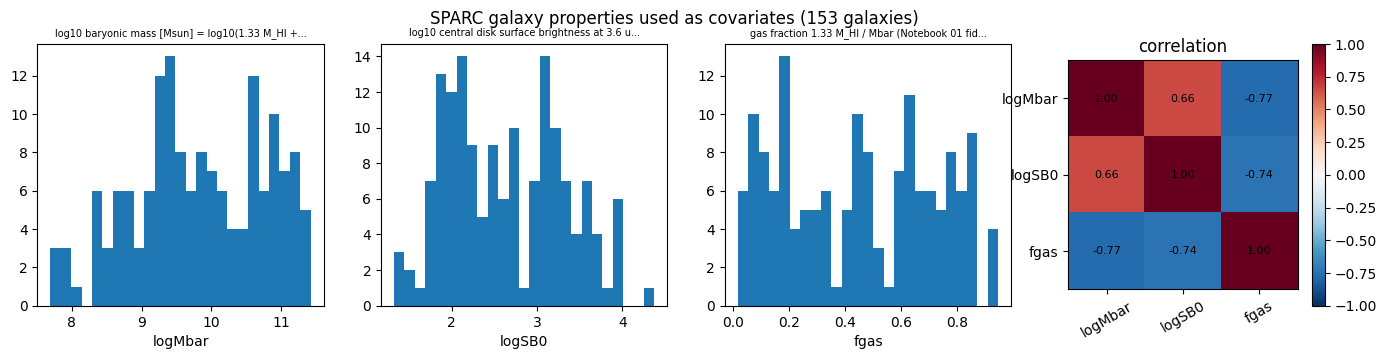

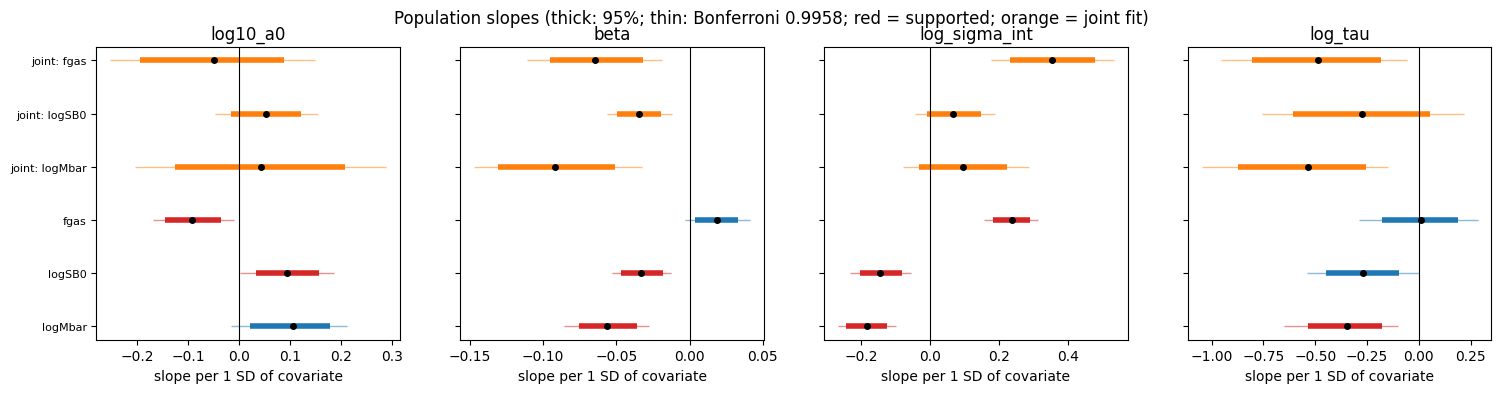

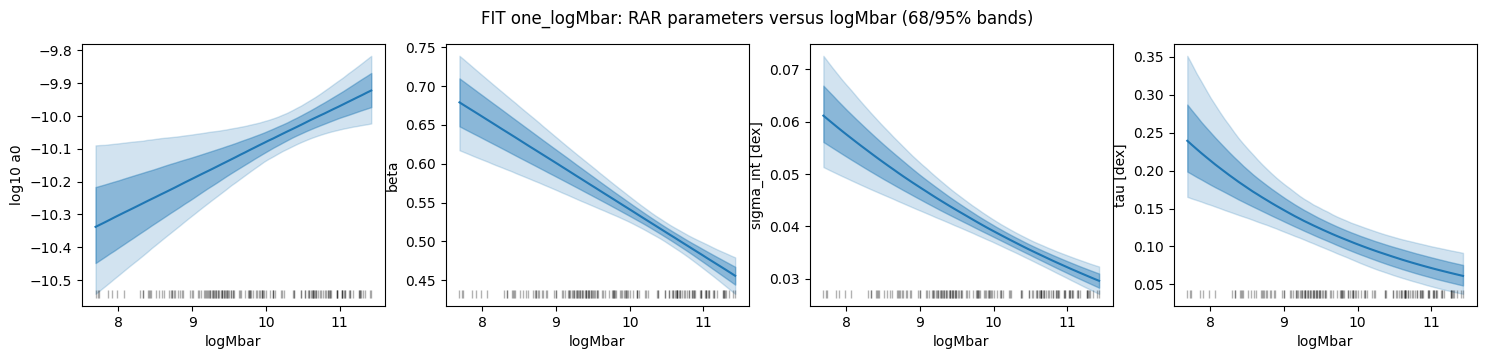

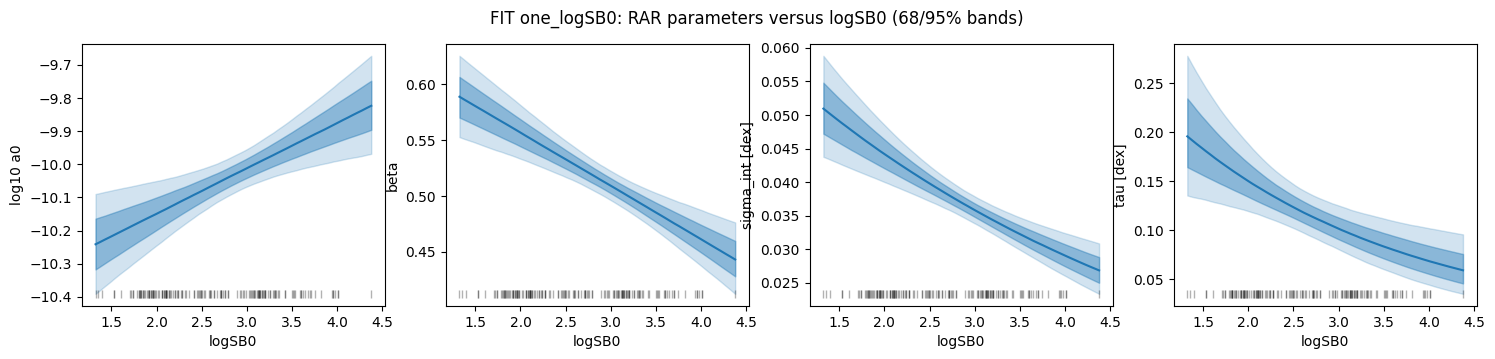

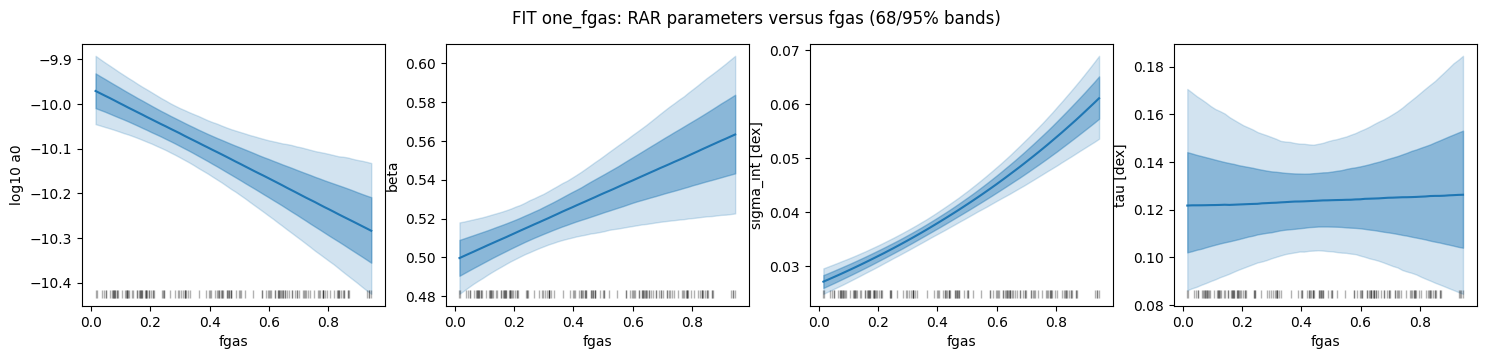

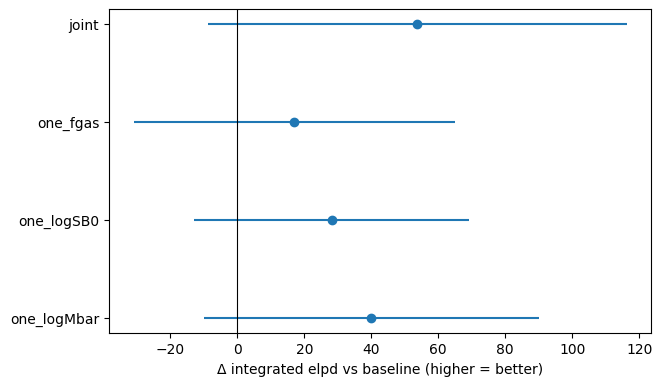

In [15]:
def savefig(fig, name):
    p = safe_path(OUT["figures"] / name); fig.savefig(p, dpi=130, bbox_inches="tight"); plt.show(); return p
# (1) covariates
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for a, c in zip(ax, COVARIATES): a.hist(cov[c], bins=25, color="C0"); a.set_xlabel(c); a.set_title(COVARIATES[c][0][:46] + "...", fontsize=7)
im = ax[3].imshow(cov_corr.values, cmap="RdBu_r", vmin=-1, vmax=1); ax[3].set_xticks(range(3)); ax[3].set_xticklabels(list(COVARIATES), rotation=30)
ax[3].set_yticks(range(3)); ax[3].set_yticklabels(list(COVARIATES)); fig.colorbar(im, ax=ax[3]); ax[3].set_title("correlation")
for i in range(3):
    for j in range(3): ax[3].text(j, i, f"{cov_corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.suptitle("SPARC galaxy properties used as covariates (153 galaxies)"); savefig(fig, "05_covariates.png")
# (2) slope forest plot: primary and joint
if len(slopes):
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
    for a, p in zip(ax, POP_PARAMS):
        t = slopes[(slopes.parameter == p) & (slopes.fit.isin([f"one_{c}" for c in COVARIATES] + ["joint"]))].reset_index(drop=True)
        for i, rr in t.iterrows():
            x = np.asarray(RESULTS[rr.fit]["mcmc"].get_samples()[f"slope_{p}"])[:, RESULTS[rr.fit]["cfg"]["covariates"].index(rr.covariate)]
            lo95, hi95 = np.quantile(x, [0.025, 0.975]); lob, hib = np.quantile(x, [ALPHA_P / 2, 1 - ALPHA_P / 2])
            col = "C3" if rr.verdict_family_wise == "SUPPORTED" else ("C1" if rr.fit == "joint" else "C0")
            a.hlines(i, lob, hib, color=col, lw=1, alpha=0.5); a.hlines(i, lo95, hi95, color=col, lw=4); a.plot(np.median(x), i, "ko", ms=4)
        a.axvline(0, color="k", lw=0.8); a.set_title(p); a.set_xlabel("slope per 1 SD of covariate")
        a.set_yticks(range(len(t))); a.set_yticklabels([f"{f.replace('one_', '')}: {c}" if f == "joint" else c for f, c in zip(t.fit, t.covariate)], fontsize=8)
    fig.suptitle(f"Population slopes (thick: 95%; thin: Bonferroni {1 - ALPHA_P:.4f}; red = supported; orange = joint fit)"); savefig(fig, "05_slope_forest.png")
# (3) theta(z) for each primary fit
for c in FITS_ONE_AT_A_TIME:
    r = RESULTS.get(f"one_{c}", {})
    if "mcmc" not in r: continue
    smp = r["mcmc"].get_samples(); zg = np.linspace(Zall[:, list(COVARIATES).index(c)].min(), Zall[:, list(COVARIATES).index(c)].max(), 60)
    xphys = COV_MEAN[c] + COV_SD[c] * zg
    curves = {"log10 a0": np.asarray(smp["log10_a0"])[:, None] + np.asarray(smp["slope_log10_a0"])[:, :1] * zg,
              "beta": np.asarray(smp["beta"])[:, None] + np.asarray(smp["slope_beta"])[:, :1] * zg,
              "sigma_int [dex]": np.asarray(smp["sigma_int"])[:, None] * np.exp(np.asarray(smp["slope_log_sigma_int"])[:, :1] * zg),
              "tau [dex]": np.asarray(smp["tau"])[:, None] * np.exp(np.asarray(smp["slope_log_tau"])[:, :1] * zg)}
    fig, ax = plt.subplots(1, 4, figsize=(18, 3.4))
    for a, (lab, cv) in zip(ax, curves.items()):
        q = np.percentile(cv, [2.5, 16, 50, 84, 97.5], axis=0)
        a.fill_between(xphys, q[0], q[4], alpha=0.2, color="C0"); a.fill_between(xphys, q[1], q[3], alpha=0.4, color="C0"); a.plot(xphys, q[2], "C0")
        a.set_xlabel(c); a.set_ylabel(lab)
        a.plot(cov[c], np.full(G, q[0].min()), "|", color="k", alpha=0.3)
    fig.suptitle(f"FIT one_{c}: RAR parameters versus {c} (68/95% bands){'' if r['stats']['converged_by_all_criteria'] else '  [NOT CONVERGED]'}")
    savefig(fig, f"05_theta_vs_{c}.png")
# (4) integrated LOO comparison
if len(loo_table) and "delta_elpd_vs_baseline" in loo_table:
    t = loo_table.dropna(subset=["delta_elpd_vs_baseline"])
    fig, ax = plt.subplots(figsize=(7, 0.6 * len(t) + 1.8)); ax.errorbar(t.delta_elpd_vs_baseline, range(len(t)), xerr=t.delta_se, fmt="o")
    ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(t))); ax.set_yticklabels(t.fit); ax.set_xlabel("Δ integrated elpd vs baseline (higher = better)")
    savefig(fig, "05_loo_comparison.png")

## 16. Exports and Report

In [16]:
cov_table.to_csv(OUT["tables"] / "05_covariates_standardised.csv", index=False)
pd.DataFrame(CHECKS).to_csv(OUT["diagnostics"] / "05_integrity_checks.csv", index=False)
config = {"run_id": RUN_ID, "created_utc": RUN_TIMESTAMP, "versions": VERSIONS, "seed": SEED, "notebook03_run_id": RUN03,
          "covariates": COVARIATES, "covariate_mean": COV_MEAN, "covariate_sd": COV_SD, "vif": vif, "pop_params": POP_PARAMS,
          "slope_prior_sd_per_SD": SLOPE_PRIOR_SD, "intercept_priors_from_nb03": PRIORS_SHARED, "beta_floor": BETA_FLOOR,
          "test_family": {"n": N_FAMILY, "family_alpha": FAMILY_ALPHA, "per_test_alpha": ALPHA_P, "normal_critical_z": ZCRIT, "definition": "12 slopes from the one-at-a-time fits"},
          "sampler": {"target_accept": TARGET_ACCEPT, "max_tree_depth": MAX_TREE_DEPTH, **FIT}, "integrated_loo": ILOO,
          "convergence_criteria": {"r_hat": RHAT_MAX, "ess_bulk": ESS_BULK_MIN, "ess_tail": ESS_TAIL_MIN, "divergences": DIVERGENCES_MAX, "bfmi": BFMI_MIN, "tree_depth_hits": 0},
          "fits": {n: {"covariates": r["cfg"]["covariates"], "slope_prior_mult": r["cfg"]["slope_prior_mult"], "seconds": r.get("seconds"),
                       "stats": r.get("stats"), "netcdf": str(r.get("nc")), "error": r.get("error")} for n, r in RESULTS.items()},
          "regression": REGRESSION, "data_checksums": {NB02[k].name: sha256_of(NB02[k]) for k in NB02}, "n_points": int(include_mask.sum()), "n_galaxies": G,
          "not_applicable": "survey offsets and cross-survey comparisons (Sec. 4.5 items 5-6): cross-survey feasibility gate did not pass (Notebook 01B)"}
(OUT["config"] / "05_population_config.json").write_text(json.dumps(config, indent=2, default=str))
pd.DataFrame([{"package": k, "version": str(v)} for k, v in VERSIONS.items()]).to_csv(OUT["config"] / "05_package_versions.csv", index=False)

chk = pd.DataFrame(CHECKS)
sup = primary[primary.verdict_family_wise == "SUPPORTED"] if len(primary) else primary
bord = primary[primary.verdict_family_wise == "borderline"] if len(primary) else primary
def line(rw): return (f"* {rw.parameter} vs {rw.covariate}: {rw.slope_per_SD_median:+.4f} ± {rw.slope_per_SD_sd:.4f} per SD "
                      f"({rw.slope_physical_median:+.4f} {rw.physical_unit}); 95% {rw.ci95}; P(>0) = {rw['P(slope>0)']:.3f} -> {rw.verdict_family_wise}")
report = f"""# Notebook 05 — Population Dependence (SPARC only) — Report

*Run {RUN_ID} ({RUN_TIMESTAMP} UTC); Notebook 03 run {RUN03}. This file exists only if the notebook ran.*

## Setup
* Model C error model (Notebook 03): independent errors with distance, inclination and Upsilon* sampled; intercept priors identical to Notebook 03.
* theta_i = theta_0 + theta_1 z_i for log10 a0, beta, ln sigma_int, ln tau; z = standardised logMbar, logSB0, fgas.
* Covariate correlations: {json.dumps({f"{a}/{b}": round(float(cov_corr.loc[a, b]), 2) for i, a in enumerate(COVARIATES) for b in list(COVARIATES)[i + 1:]})}; VIF {json.dumps({k: round(v, 2) for k, v in vif.items()})}.
* Regression (zero slopes vs Notebook 03 saved Model C): max |diff| {REGRESSION["max_abs_diff_vs_saved_NB03"]:.2e}.
* Declared test family: {N_FAMILY} slopes (one-at-a-time fits); Bonferroni per-test alpha {ALPHA_P:.4f} (|z| > {ZCRIT:.2f}).

## Convergence
{chr(10).join(f"* {rw.fit}: converged={rw.converged_by_all_criteria}; max R-hat {rw.max_r_hat_all:.4f}; ESS {rw.min_ess_bulk_all:.0f}/{rw.min_ess_tail_all:.0f}; divergences {rw.divergences}; {rw.minutes:.1f} min" for rw in fit_status.itertuples() if not rw.error) }

## Primary result (declared family)
**Supported dependences:** {len(sup)} of {N_FAMILY}.
{chr(10).join(line(rw) for _, rw in sup.iterrows()) or "* none"}

**Borderline (the two estimates of the extreme interval disagree):**
{chr(10).join(line(rw) for _, rw in bord.iterrows()) or "* none"}

All slopes: `tables/05_slopes_all_fits.csv`. Prior sensitivity (slope prior SD x2): `tables/05_slope_prior_sensitivity.csv`.

## Predictive comparison (integrated galaxy-level LOO)
{chr(10).join(f"* {rw['fit']}: elpd {rw['elpd_integrated_loo']:.1f} (SE {rw['se']:.1f}); galaxies with Pareto k>0.7: {rw['n_k_gt_0.7']}" + (f"; delta vs baseline {rw['delta_elpd_vs_baseline']:+.1f} (SE {rw['delta_se']:.1f})" if pd.notna(rw.get('delta_elpd_vs_baseline', np.nan)) else "") for _, rw in loo_table.iterrows())}

## Caveats
* SPARC only; survey effects cannot be separated (cross-survey gate not passed).
* Independent-error model. Under correlated errors (Notebook 04) sigma_int collapses toward zero, so the sigma_int dependence is specific to Model C.
* Covariates are catalogue-based (fixed distance, fiducial Upsilon* = 0.5) and strongly correlated; the joint fit is secondary.
* Detection limits for these slopes come from injection-recovery (Notebook 06). A null result here is not evidence of universality until those limits are known.

## Checks
{len(chk)} checks: {int((chk.status == "FAIL").sum())} FAIL, {int((chk.status == "WARN").sum())} WARN.
"""
rep = OUT["tables"] / "05_Population_Dependence_Report.md"; rep.write_text(report, encoding="utf-8")
manifest = pd.DataFrame([{"file": str(p.relative_to(OUT_ROOT)), "bytes": p.stat().st_size} for p in sorted(OUT_ROOT.rglob("*")) if p.is_file()])
manifest.to_csv(OUT["config"] / "05_output_manifest.csv", index=False)
print(report); print("Outputs:", OUT_ROOT)
if IN_KAGGLE:
    import shutil; shutil.make_archive(f"/kaggle/working/05_Population_{RUN_ID}", "zip", root_dir=OUT_ROOT.parent, base_dir=OUT_ROOT.name)

# Notebook 05 — Population Dependence (SPARC only) — Report

*Run 20261027T161151Z (2026-10-27T16:11:51Z UTC); Notebook 03 run 20261022T095735Z. This file exists only if the notebook ran.*

## Setup
* Model C error model (Notebook 03): independent errors with distance, inclination and Upsilon* sampled; intercept priors identical to Notebook 03.
* theta_i = theta_0 + theta_1 z_i for log10 a0, beta, ln sigma_int, ln tau; z = standardised logMbar, logSB0, fgas.
* Covariate correlations: {"logMbar/logSB0": 0.66, "logMbar/fgas": -0.77, "logSB0/fgas": -0.74}; VIF {"logMbar": 2.56, "logSB0": 2.32, "fgas": 3.21}.
* Regression (zero slopes vs Notebook 03 saved Model C): max |diff| 2.37e-12.
* Declared test family: 12 slopes (one-at-a-time fits); Bonferroni per-test alpha 0.0042 (|z| > 2.87).

## Convergence
* baseline: converged=True; max R-hat 1.0051; ESS 3812/1836; divergences 0; 6.3 min
* one_logMbar: converged=True; max R-hat 1.0038; ESS 1514/661; divergences 0; 9.0 min
* one_logSB0: conver